In [257]:
import numpy as np              # Одномерные и многомерные массивы (array)
import pandas as pd             # Таблицы и временные ряды (dataframe, series)
import matplotlib.pyplot as plt # Научная графика
import seaborn as sns           # Еще больше красивой графики для визуализации данных
import sklearn                  # Алгоритмы машинного обучения
from sklearn.model_selection import train_test_split

# 0. Описание задачи

Цель — построить модель машинного обучения, которая по характеристикам объявления Airbnb предсказывает стоимость одной ночи (`price`). Используем доступные до бронирования признаки: географические координаты, район, тип жилья, минимальное число ночей, количество отзывов, частоту отзывов и доступность жилья.


# 1. Чтение данных
Файл AB_NYC_2019.csv лежит в репозитории GitHub. К файлу можно обратиться по ссылке https://raw.githubusercontent.com/Kosolapov-Vitaliy/unn_ml_2026/refs/heads/firstbranch/AB_NYC_2019.csv.

In [258]:
url = "https://raw.githubusercontent.com/Kosolapov-Vitaliy/unn_ml_2026/refs/heads/firstbranch/AB_NYC_2019.csv"
data_raw = pd.read_csv(url)

Посмотрим сколько строк и стобцов содержит таблица, для этого выполним следующую команду:

In [259]:
data_raw.shape

(48895, 16)

Отсюда мы видим, что в таблице содержится 48895 строк и 16 столбцов.
Посмотрим на первые и последние строки, а также на на несколько произвольных.

In [260]:
data_raw

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [261]:
data_raw.sample(10)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
41318,32171100,Cozy Room in uptown Manhattan,241366980,Josefina,Manhattan,Washington Heights,40.83685,-73.94176,Private room,75,2,20,2019-07-02,4.88,1,223
3745,2254851,Sunny and Bright 1BR Factory Loft,7503643,Vida,Brooklyn,Greenpoint,40.72599,-73.94172,Entire home/apt,149,30,4,2019-04-20,0.09,52,330
5547,4033521,Brooklyn 1 BR Near Subway,1369577,Thomas & Gaby,Brooklyn,Crown Heights,40.67441,-73.92371,Entire home/apt,60,6,144,2019-06-18,2.50,2,59
42490,32980398,"Your own sanctuary! Private Floor, 3min to subway",5338560,Daniella,Brooklyn,Bedford-Stuyvesant,40.67812,-73.91465,Entire home/apt,95,2,14,2019-07-07,4.20,1,275
42520,33005220,Spend a Night or Seven with a Living NYC Artist!,248404100,Ligel,Bronx,Morris Heights,40.84615,-73.91546,Private room,35,1,25,2019-07-07,7.08,1,241
22728,18393354,Midtown Sanctuary,2845,Jennifer,Manhattan,Midtown,40.75358,-73.99190,Shared room,99,1,1,2018-07-18,0.08,2,365
21801,17524047,Luxe Large Suite w/Views bathroom en suite,118695056,Cameron & Dione,Brooklyn,Downtown Brooklyn,40.69250,-73.98613,Private room,153,3,28,2019-06-09,1.00,2,11
21480,17173473,Ocean Blue Room,113558977,Joe,Queens,Rego Park,40.72650,-73.86017,Private room,30,1,120,2019-06-11,4.10,2,112
30165,23271736,Cozy Brooklyn Heights Apartment!,47151333,Walter,Brooklyn,Brooklyn Heights,40.69061,-73.99264,Entire home/apt,113,3,4,2019-03-31,0.25,2,0
43988,33986797,Cozy room in Richmond hill,251768799,Naiomi,Queens,Richmond Hill,40.69927,-73.82643,Private room,150,1,1,2019-04-25,0.40,1,0


Посмотрим информацию о таблице:

In [262]:
data_raw.info()
print("\nТипы признаков:")
data_raw.dtypes.to_frame("dtype")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

,dtype
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


In [263]:
data['room_type']=data['room_type'].astype('category')
data['neighbourhood_group']=data['neighbourhood_group'].astype('category')
data['neighbourhood']=data['neighbourhood'].astype('category')

Мы видим, что столбцы (признаки) имеют имена:

* `id` — идентификатор объявления

* `name` — текстовое название объявления

* `host_id` — идентификатор хоста

* `host_name` — имя хоста

* `neighbourhood_group` — крупный район города (например, Manhattan, Brooklyn, Queens, Bronx, Staten Island)

* `neighbourhood` — конкретный район внутри `neighbourhood_group`

* `latitude` — географическая широта объекта

* `longitude` — географическая долгота объекта

* `room_type` — тип жилья ('Entire home/apt' — вся квартира/апартаменты, 'Private room' — отдельная комната, 'Shared room' — общая комната)

* `price` — цена за ночь (в долларах США)

* `minimum_nights` — минимальное количество ночей для бронирования

* `number_of_reviews` — количество отзывов об объявлении

* `last_review` — дата последнего отзыва

* `reviews_per_month` — среднее количество отзывов в месяц

* `calculated_host_listings_count` — количество объявлений у данного хоста

* `availability_365` — количество дней в году, когда объявление доступно для бронирования



Признак `room_type` — номинальный (категориальный), `neighbourhood_group` — номинальный (категориальный), `neighbourhood` — номинальный (категориальный с большим числом уровней). Признаки `id`, `host_id` — числовые идентификаторы. Признак `last_review` — дата. Остальные признаки, включая целевой признак `price`, — количественные (числовые). Текстовые признаки `name` и `host_name` являются номинальными (строковыми) и требуют специальной обработки или исключения.

Требуется предсказать количественный признак `price` по остальным признакам. Это задача восстановления регрессии.

### Подготавливаем целевую переменную

Целевая переменная — `price`, цена за ночь в долларах США. В данном датасете у `price` нет пропусков, но встречаются объявления с ценой `0`. Исключим записи с отсутствующей или неположительной целевой переменной. А также исключим записи с ценой превышающей 5000 $, предпологая, что это ошибки.

In [264]:
data = data_raw.copy()
data["price"] = pd.to_numeric(data["price"], errors="coerce")

PRICE_MAX = 5000
n_before = len(data)
invalid_price = data["price"].isna() | (data["price"] <= 0)
high_price = data["price"] > PRICE_MAX

print("Строк до фильтрации:", n_before)
print("Строк с пропущенной или неположительной price:", int(invalid_price.sum()))
print(f"Строк с price > ${PRICE_MAX:,}:", int(high_price.sum()))
print(f"Доля объявлений с price > ${PRICE_MAX:,}: {100 * high_price.sum() / n_before:.4f}%")
exclude_price = invalid_price | high_price
data = data.loc[~exclude_price].copy().reset_index(drop=True)
print("Строк после фильтрации:", len(data))
print("Всего удалено строк:", n_before - len(data))
print("Максимальная цена после фильтрации:", data["price"].max())
display(data["price"].describe(percentiles=[.25, .5, .75, .90, .95, .99, .995]).to_frame())

Строк до фильтрации: 48895
Строк с пропущенной или неположительной price: 11
Строк с price > $5,000: 20
Доля объявлений с price > $5,000: 0.0409%
Строк после фильтрации: 48864
Всего удалено строк: 31
Максимальная цена после фильтрации: 5000


,price
count,48864.000000
mean,149.660466
std,181.973179
min,10.000000
25%,69.000000
50%,106.000000
75%,175.000000
90%,269.000000
95%,350.000000
99%,750.000000


### Выбираем признаки для модели

Не каждый столбец с числовым типом полезен как числовой признак:

- `id` и `host_id` — идентификаторы, их величина не означает «больше/меньше» жилья или качества. Удалим их.
- `name` и `host_name` — свободный текст/имена, не будем рассматривать.
- `last_review` — дата последнего отзыва. На данный момент исключим её, так как число отзывов и частота отзывов уже дают простую (и вероятно достаточную) информацию об активности объявления.
- `neighbourhood_group`, `neighbourhood`, `room_type` — категориальные признаки.
- Координаты `latitude` и `longitude` считаем числовыми признаками. Они могут отражать разницу между местоположениями.

Сохраним `reviews_per_month` как числовой признак. Проверка исходного набора данных показывает, что его пропуски совпадают с объявлениями без отзывов, поэтому далее заполним эти значения нулём и добавим индикатор `has_reviews`.

In [265]:
missing_rpm = data["reviews_per_month"].isna()
print("Пропуски reviews_per_month:", int(missing_rpm.sum()))
print("Из них с number_of_reviews == 0:", int((data.loc[missing_rpm, "number_of_reviews"] == 0).sum()))
print("Из них с number_of_reviews > 0:", int((data.loc[missing_rpm, "number_of_reviews"] > 0).sum()))
data["reviews_per_month"] = data["reviews_per_month"].fillna(0)
data["has_reviews"] = (data["number_of_reviews"] > 0).astype(int)
NUM_FEATURES = [
    "latitude", "longitude", "minimum_nights", "number_of_reviews",
    "reviews_per_month", "calculated_host_listings_count", "availability_365",
    "has_reviews"
]
CAT_FEATURES = ["neighbourhood_group", "neighbourhood", "room_type"]
TARGET = "price"
X = data[NUM_FEATURES + CAT_FEATURES].copy()
y = data[TARGET].copy()
print("Числовых признаков:", len(NUM_FEATURES), NUM_FEATURES)
print("Категориальных признаков:", len(CAT_FEATURES), CAT_FEATURES)
print("Размер X:", X.shape)
print("Цель y:", TARGET)

Пропуски reviews_per_month: 10040
Из них с number_of_reviews == 0: 10040
Из них с number_of_reviews > 0: 0
Числовых признаков: 8 ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'has_reviews']
Категориальных признаков: 3 ['neighbourhood_group', 'neighbourhood', 'room_type']
Размер X: (48864, 11)
Цель y: price


# 2. Разбиение данных на обучающую и тестовую выборки
Разделим на тестовую и обучающую выборки. Так как регрессия идёт по признаку `price`, то перед разделением убираем все пустые ячейки из `price` и ячейки с неположительными значениями.

In [266]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Доля train:", round(len(X_train) / len(X), 3))
print("Доля test:", round(len(X_test) / len(X), 3))

Train: (39091, 11)  Test: (9773, 11)
Доля train: 0.8
Доля test: 0.2


# 3. Визуализация данных. Вычесление основных характеристик.

Статистики ниже считаем на обучающей выборке. Среднее и стандартное отклонение описывают центр и разброс, медиана и квартили устойчивее к очень дорогим объявлениям.

In [267]:
train_data = X_train.copy()
train_data["price"] = y_train
train_data["log_price"] = np.log1p(y_train)

numeric_summary = train_data[NUM_FEATURES + ["price"]].describe().T
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
latitude,39091.0,40.728836,0.054562,40.49979,40.689930,40.72293,40.76316,40.91306
longitude,39091.0,-73.952261,0.046203,-74.24442,-73.983105,-73.95570,-73.93644,-73.71299
minimum_nights,39091.0,6.971528,19.465644,1.00000,1.000000,3.00000,5.00000,1000.00000
number_of_reviews,39091.0,23.310404,44.492076,0.00000,1.000000,5.00000,24.00000,607.00000
reviews_per_month,39091.0,1.093157,1.607182,0.00000,0.040000,0.37000,1.58000,58.50000
calculated_host_listings_count,39091.0,7.147655,33.010050,1.00000,1.000000,1.00000,2.00000,327.00000
availability_365,39091.0,112.799493,131.586377,0.00000,0.000000,45.00000,227.00000,365.00000
has_reviews,39091.0,0.795145,0.403601,0.00000,1.000000,1.00000,1.00000,1.00000
price,39091.0,149.298381,178.718009,10.00000,69.000000,105.00000,175.00000,5000.00000


In [268]:
train_data['room_type']=train_data['room_type'].astype('category')
train_data['neighbourhood_group']=train_data['neighbourhood_group'].astype('category')
train_data['neighbourhood']=train_data['neighbourhood'].astype('category')


In [269]:
price_summary = train_data["price"].agg(["count", "mean", "median", "std", "min", "max", "skew"])
price_summary["IQR"] = train_data["price"].quantile(0.75) - train_data["price"].quantile(0.25)
price_summary["q25"] = train_data["price"].quantile(0.25)
price_summary["q75"] = train_data["price"].quantile(0.75)
display(price_summary.to_frame("Значение"))

,Значение
count,39091.000000
mean,149.298381
median,105.000000
std,178.718009
min,10.000000
max,5000.000000
skew,9.567555
IQR,106.000000
q25,69.000000
q75,175.000000


Интерпретация: среднее выше медианы — это признак правосторонней асимметрии, вероятно, из-за небольшого числа дорогих объявлений. Стандартное отклонение показывает типичный масштаб разброса относительно среднего, но чувствительно к выбросам.

### Распределение цены

Сравним распределение цены в исходном масштабе и после преобразования `log1p(price)`. Логарифм часто уменьшает влияние длинного правого хвоста.


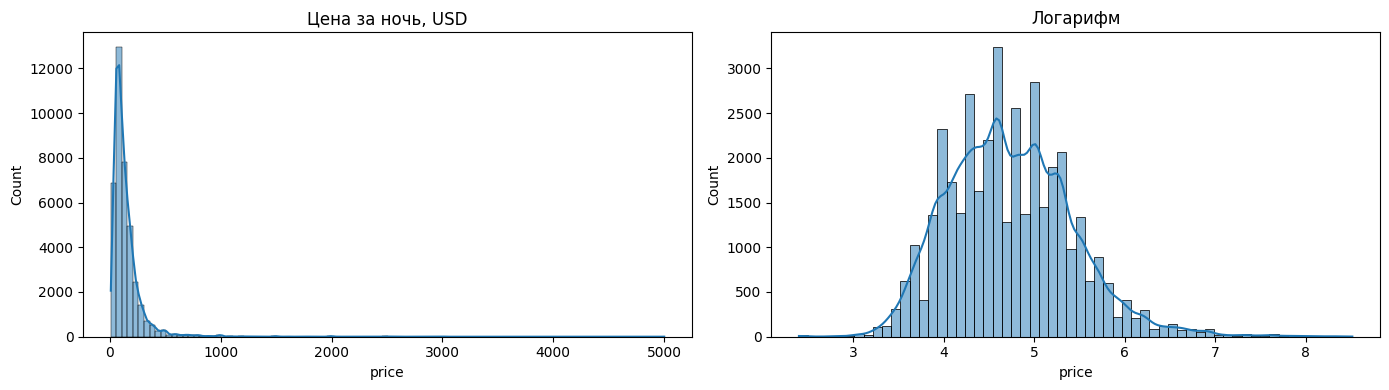

In [270]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train_data["price"], bins=100,kde=True, ax=axes[0])
axes[0].set_title("Цена за ночь, USD")
sns.histplot(np.log1p(train_data["price"]), bins=60,kde=True, ax=axes[1])
axes[1].set_title("Логарифм")
plt.tight_layout()
plt.show()

Мы видим, что на графике распределение цены сконцентрировано слева, что показывает наличие редких, но дорогих объявлений (которые могут быть выбросами). График логарифма в свою очередь показывает, что-то визуально похожее на график нормального распределения. Пиковое значение на графике логарифма соответствует ~ 90$

In [271]:
train_data['price'].agg(['mean', 'median', 'std', 'skew']), np.log1p(train_data['price']).agg(['mean', 'median', 'std', 'skew'])

(mean      149.298381
 median    105.000000
 std       178.718009
 skew        9.567555
 Name: price, dtype: float64,
 mean      4.734375
 median    4.663439
 std       0.686649
 skew      0.557749
 Name: price, dtype: float64)

Распределение цены скошено вправо: среднее заметно больше медианы, коэффициент асимметрии ≈ 18.6. Логарифм цены распределён гораздо симметричнее, асимметрия ≈ 0.6.

### Категориальные признаки: тип жилья и район

Категориальные признаки сравним через частоты и медианные цены. Для диаграммы «ящик с усами» ограничиваем отображение 95-м процентилем цены, чтобы редкие дорогие объявления не сплющивали остальную часть графика.

In [272]:
print("Количество объявлений по room_type:")
display(train_data["room_type"].value_counts().to_frame("Количество"))

Количество объявлений по room_type:


,Количество
room_type,
Entire home/apt,20285
Private room,17873
Shared room,933


In [273]:
print("Цена по типу жилья:")
display(train_data.groupby("room_type", observed=True)["price"].agg(["count", "median", "mean"]).sort_values("median", ascending=False))

Цена по типу жилья:


,count,median,mean
room_type,,,
Entire home/apt,20285,160.0,207.018585
Private room,17873,70.0,87.886253
Shared room,933,45.0,70.803859


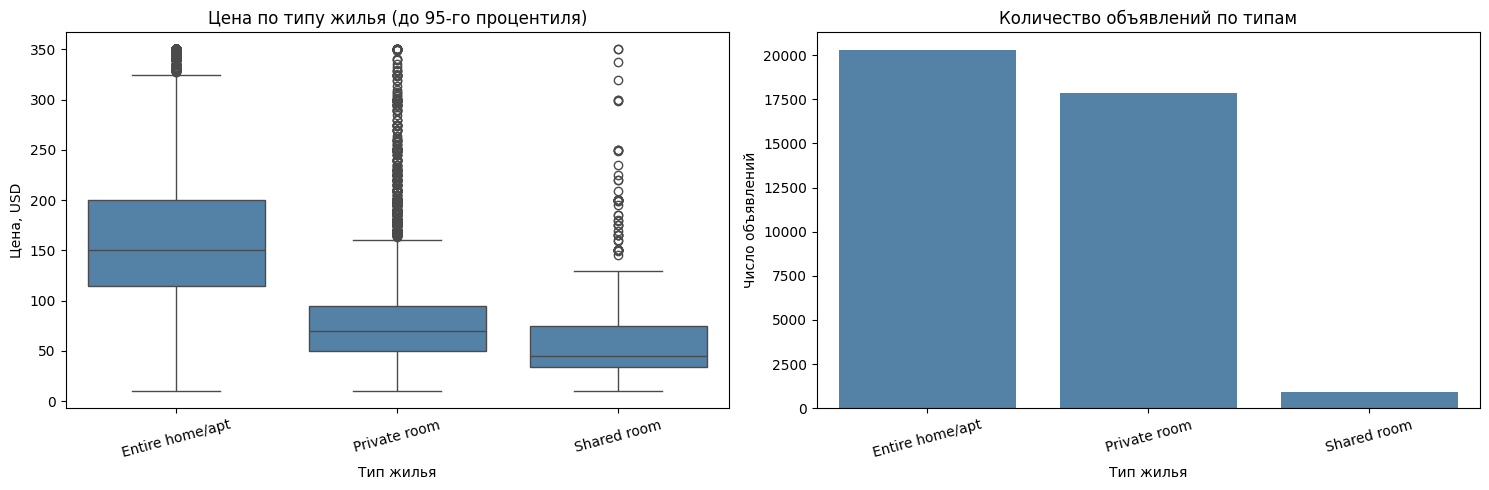

In [274]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_cap = train_data["price"].quantile(0.95)
plot_data = train_data.loc[train_data["price"] <= plot_cap]
sns.boxplot(data=plot_data, x="room_type", y="price", ax=axes[0], color="steelblue")
axes[0].set_title("Цена по типу жилья (до 95-го процентиля)")
axes[0].set_xlabel("Тип жилья")
axes[0].set_ylabel("Цена, USD")
axes[0].tick_params(axis="x", rotation=15)

sns.countplot(data=train_data, x="room_type", order=train_data["room_type"].value_counts().index, ax=axes[1], color="steelblue")
axes[1].set_title("Количество объявлений по типам")
axes[1].set_xlabel("Тип жилья")
axes[1].set_ylabel("Число объявлений")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

Можно заметить, что цена за дом/аппартаменты сильно выше, чем за общую или частную комнату.

### Цена по группам районов

`neighbourhood_group` содержит пять крупных групп районов Нью-Йорка. Сравним объём данных и типичную цену в каждой группе. Групповые различия могут отражать местоположение, тип жилья и другие одновременно меняющиеся характеристики.

In [275]:
group_summary = train_data.groupby("neighbourhood_group", observed=True)["price"].agg(["count", "median", "mean"]).sort_values("median", ascending=False)
group_summary



,count,median,mean
neighbourhood_group,,,
Manhattan,17299,150.0,191.593098
Brooklyn,16093,90.0,123.055676
Queens,4509,75.0,96.508538
Staten Island,302,75.0,94.917219
Bronx,888,65.0,87.496622


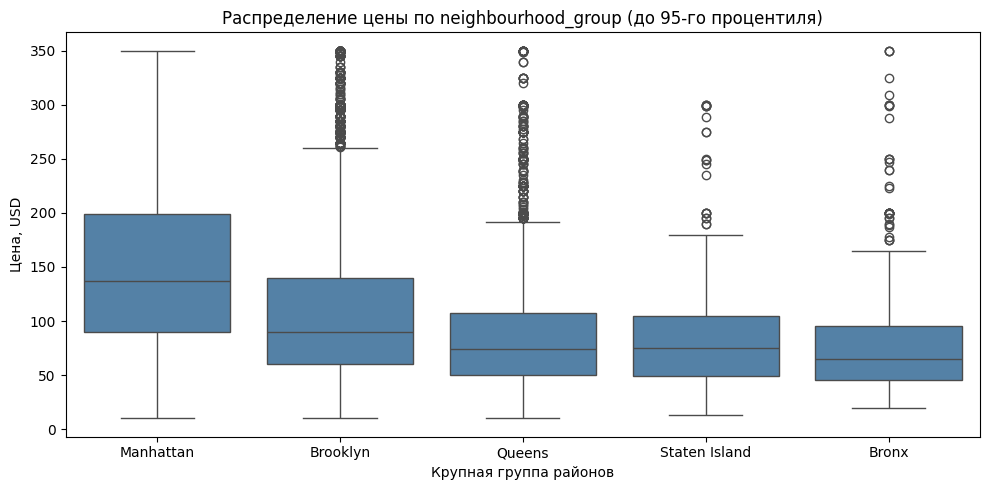

In [276]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_data, x="neighbourhood_group", y="price", order=group_summary.index, color="steelblue")
plt.title("Распределение цены по neighbourhood_group (до 95-го процентиля)")
plt.xlabel("Крупная группа районов")
plt.ylabel("Цена, USD")
plt.tight_layout()
plt.show()

Можно заметить, что жильё в Манхетане значительно дороже, чем в остальных крупных районах. После Манхеттана выделяется Бруклин. Оставшиеся три района находятся на достаточно сопостовимом уровне.

### Зависимость от минимального срока аренды.


In [277]:
train_data['minimum_nights'].value_counts().head()

,count
minimum_nights,
1,10174
2,9371
3,6396
30,2978
4,2601


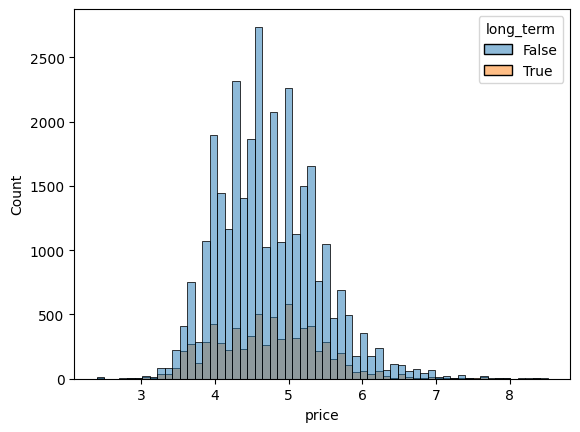

In [278]:
train_data['long_term'] = train_data['minimum_nights'] >= 7
sns.histplot(x=np.log1p(train_data["price"]), hue='long_term', data=train_data, bins=60)
plt.show()


Можно заметить, что прямой зависимости в стоимости от минимального количества ночей нет. Количество долгосрочных и краткосрочных предложений сопостовимы по распределению на шкале логарифма стоимости(На обычной стоимости рассматривать сложно, т.к. все значения концентрируются в левой части).

### Географическое расположение объявлений

Широта и долгота потенциально важны: цены могут зависеть от близости к центру, транспорту и туристическим местам. Ниже — карта рассеяния координат. Цвет цены ограничен 95-м процентилем **только для цвета на рисунке**, чтобы не потерять контраст у основной массы объявлений.

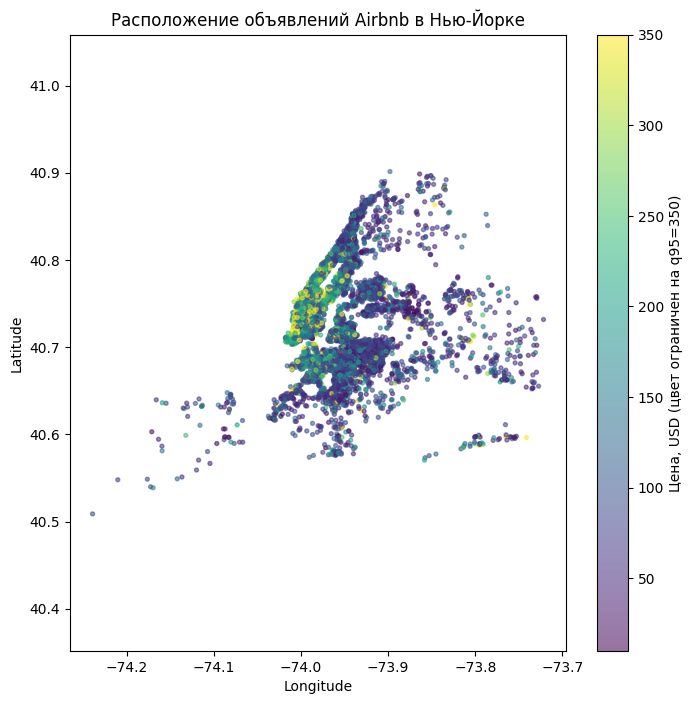

In [279]:
geo_sample = train_data.sample(n=min(8000, len(train_data)), random_state=42)
color_cap = train_data["price"].quantile(0.95)
point_colors = np.clip(geo_sample["price"].to_numpy(), 0, color_cap)

plt.figure(figsize=(8, 8))
sc = plt.scatter(
    geo_sample["longitude"], geo_sample["latitude"],
    c=point_colors, cmap="viridis", s=8, alpha=0.55
)
plt.colorbar(sc, label=f"Цена, USD (цвет ограничен на q95={color_cap:.0f})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Расположение объявлений Airbnb в Нью-Йорке")
plt.axis("equal")
plt.show()

Это картина, соответствует раннее сделанным выводам, что наиболее дорогое жильё в Манхеттане. А также показывает, что жильё в соседних районах, которое находится ближе к Манхеттану стоит дороже.

### Корреляционная матрица
Вычислим корреляционную матрицу

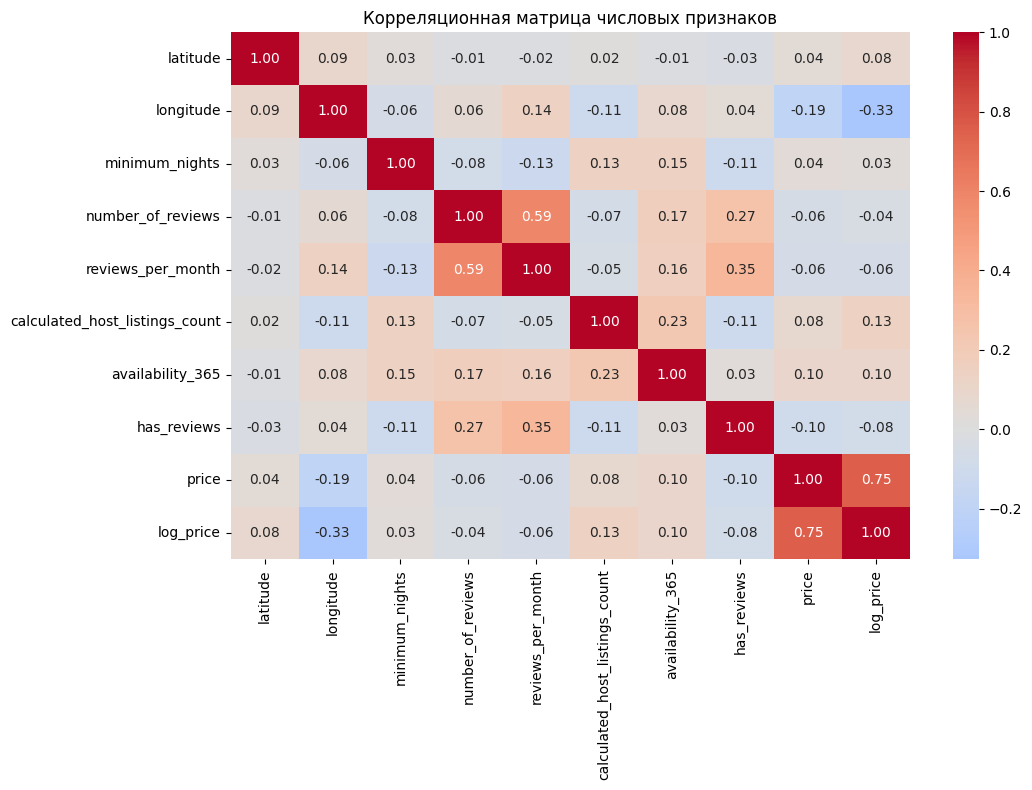

In [280]:
corr_columns = NUM_FEATURES + ["price", "log_price"]
corr_mat = train_data[corr_columns].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

## 4. Выбросы

Невалидные записи (неправдоподобные цены и размеры) мы уже удалили. Но и среди оставшихся признаков есть признаки с очень тяжёлыми хвостами. Посмотрим на ящики с усами для некоторых из них:

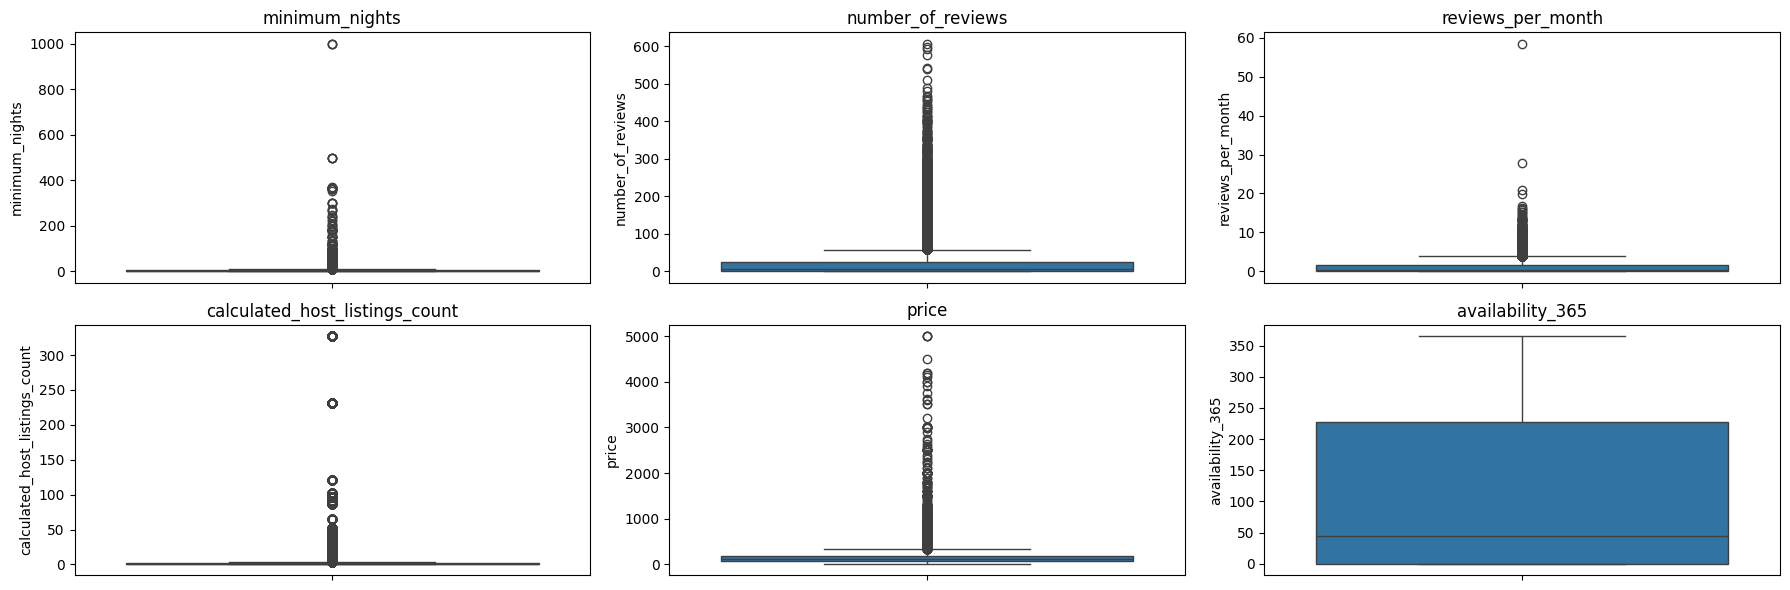

In [281]:
heavy = ['minimum_nights', 'number_of_reviews', 'reviews_per_month',
         'calculated_host_listings_count', 'price', 'availability_365']
fig, axes = plt.subplots(2, 3, figsize=(18, 6))
for ax, col in zip(axes.ravel(), heavy):
    sns.boxplot(y=train_data[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
pass


Выброс — наблюдение, сильно отличающееся от основной массы данных. Для первичного поиска воспользуемся правилом Тьюки: значение ниже `Q1 − 1.5 × IQR` или выше `Q3 + 1.5 × IQR` считается потенциальным выбросом. Целевую переменную будем моделировать через `log1p(price)`, а экстремальные значения числовых признаков ограничим по 1-му и 99-му процентилям, рассчитанным только на обучающей выборке.

In [282]:
def tukey_outlier_table(frame, columns):
    rows = []
    for col in columns:
        s = frame[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((s < low) | (s > high)).sum())
        rows.append({
            "признак": col, "Q1": q1, "Q3": q3, "IQR": iqr,
            "нижняя граница": low, "верхняя граница": high,
            "потенциальных выбросов": n_out,
            "доля, %": 100 * n_out / len(s) if len(s) else np.nan
        })
    return pd.DataFrame(rows).set_index("признак")

outlier_table = tukey_outlier_table(train_data, NUM_FEATURES + ["price"])
display(outlier_table.round(3))

,Q1,Q3,IQR,нижняя граница,верхняя граница,потенциальных выбросов,"доля, %"
признак,,,,,,,
latitude,40.690,40.763,0.073,40.580,40.873,333,0.852
longitude,-73.983,-73.936,0.047,-74.053,-73.866,2266,5.797
minimum_nights,1.000,5.000,4.000,-5.000,11.000,5250,13.430
number_of_reviews,1.000,24.000,23.000,-33.500,58.500,4848,12.402
reviews_per_month,0.040,1.580,1.540,-2.270,3.890,2664,6.815
calculated_host_listings_count,1.000,2.000,1.000,-0.500,3.500,5700,14.581
availability_365,0.000,227.000,227.000,-340.500,567.500,0,0.000
has_reviews,1.000,1.000,0.000,1.000,1.000,8008,20.486
price,69.000,175.000,106.000,-90.000,334.000,2357,6.030


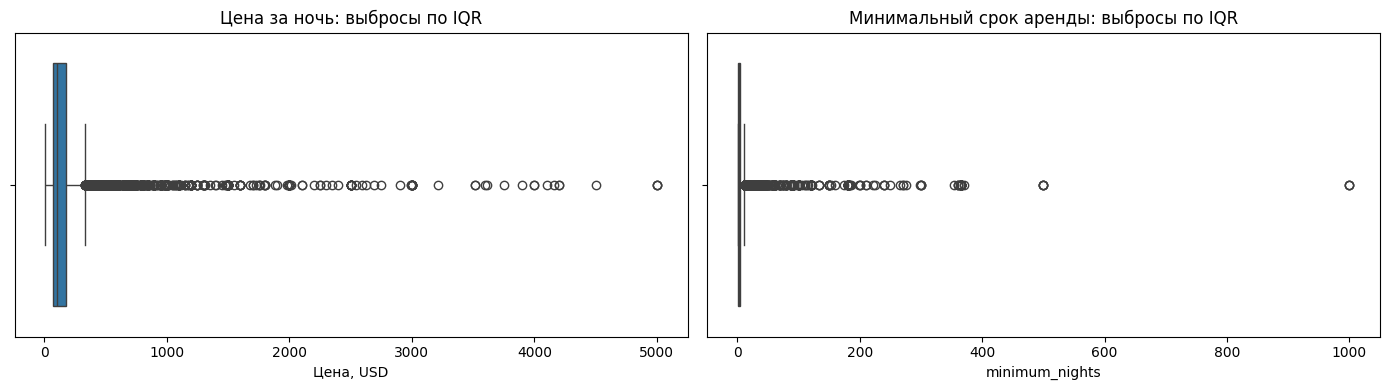

Квантили minimum_nights:


,Значение
0.00,1.0
0.50,3.0
0.90,28.0
0.95,30.0
0.99,45.0
1.00,1000.0


In [283]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=train_data["price"], ax=axes[0])
axes[0].set_title("Цена за ночь: выбросы по IQR")
axes[0].set_xlabel("Цена, USD")

sns.boxplot(x=train_data["minimum_nights"], ax=axes[1])
axes[1].set_title("Минимальный срок аренды: выбросы по IQR")
axes[1].set_xlabel("minimum_nights")
plt.tight_layout()
plt.show()

print("Квантили minimum_nights:")
display(train_data["minimum_nights"].quantile([0, .5, .9, .95, .99, 1]).to_frame("Значение"))

**Решение по выбросам:**

1. `price <= 0` и `price > 5000` исключили как не подходящую для задачи целевую переменную.
2. Остальные большие значения цены не удаляем автоматически, поскольку они могут быть реальными.
3. Для распределения цены используем `log1p`, что уменьшает влияние длинного хвоста.
4. Для числовых входных признаков в пайплайне ограничиваем крайние значения по квантилям 1% и 99%.

## 5. Пропущенные значения

Сначала разделим пропуски в исходной таблице и в признаках, которые действительно использует модель. В исходных данных часто отсутствуют `last_review` и `reviews_per_month`: у объявления без отзывов нет даты последнего отзыва и средней частоты отзывов. `last_review` в базовую модель не включаем; `reviews_per_month` заполнили нулём после проверки, что все эти пропуски соответствуют `number_of_reviews == 0`.


In [284]:
model_missing = X_train.isna().sum().sort_values(ascending=False)
model_missing = model_missing[model_missing > 0]
if len(model_missing):
    display(model_missing.to_frame("Пропущено в X_train"))
else:
    print("В выбранных признаках X_train пропущенных значений нет.")

В выбранных признаках X_train пропущенных значений нет.


## 6. Категориальные признаки
В этой работе используем:

- `room_type` — три типа жилья;
- `neighbourhood_group` — пять крупных групп районов;
- `neighbourhood` — множество локальных районов.

In [285]:
for col in CAT_FEATURES:
    print(f"\n{col}: уникальных категорий = {data[col].nunique()}")
    display(data[col].value_counts().head(15).to_frame("Количество"))


neighbourhood_group: уникальных категорий = 5


,Количество
neighbourhood_group,
Manhattan,21645
Brooklyn,20091
Queens,5665
Bronx,1090
Staten Island,373



neighbourhood: уникальных категорий = 221


,Количество
neighbourhood,
Williamsburg,3919
Bedford-Stuyvesant,3710
Harlem,2658
Bushwick,2462
Upper West Side,1968
Hell's Kitchen,1958
East Village,1853
Upper East Side,1796
Crown Heights,1564



room_type: уникальных категорий = 3


,Количество
room_type,
Entire home/apt,25391
Private room,22315
Shared room,1158


## 7. Нормализация

**Почему нужна нормализация?** KNN выбирает соседей по расстоянию. Без масштабирования признаки с большим числовым разбросом, например `minimum_nights`, могут доминировать над координатами или индикатором `has_reviews`. Используем `StandardScaler`: вычитаем среднее и делим на стандартное отклонение, вычисленные по train.

Категориальные признаки сначала заполняем самым частым значением (на случай пропуска), затем кодируем через `OneHotEncoder`. Бинарные one-hot признаки оставляем в масштабе 0/1: непрерывные числовые признаки стандартизируем отдельно.

In [286]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor(num_features=NUM_FEATURES, cat_features=CAT_FEATURES):
    return ColumnTransformer([
        ("num", make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler()
        ), num_features),
        ("cat", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)
        ), cat_features)
    ])

preprocessor = make_preprocessor()
X_train_transformed = preprocessor.fit_transform(X_train)
print("Исходная матрица:", X_train.shape)
print("После кодирования/нормализации:", X_train_transformed.shape)
print("Тип матрицы:", type(X_train_transformed).__name__)


Исходная матрица: (39091, 11)
После кодирования/нормализации: (39091, 139)
Тип матрицы: csr_matrix


После One-Hot Encoding число столбцов стало больше. Для neighbourhood категорий много, а min_frequency=20 объединяет редкие уровни. Число преобразованных столбцов выводится кодом.

## 8. Регрессия методом k ближайших соседей (KNN)

**Идея KNN:** для нового объявления модель находит `k` наиболее похожих объявлений в обучающей выборке и усредняет их целевые значения.
**Почему KNN:** Цена жилья во многом определяется тем, где оно и какое оно, — а похожие объявления (рядом на карте, с той же вместимостью, тем же типом жилья) стоят похоже. Это ровно та идея, на которой основан метод ближайших соседей: прогноз — среднее значение цены по k наиболее похожим объявлениям обучающей выборки.

**Преимущества:** простая идея, мало предположений о форме зависимости, есть понятный гиперпараметр `k`.  
**Недостатки:** чувствителен к масштабу признаков и выбору признаков, хранит обучающие объекты, а прогноз может быть медленным на больших наборах данных.

Цену обучаем в масштабе `log1p(price)`. Это уменьшает влияние очень дорогих объявлений на обучение. Для метрик и интерпретации прогноза вернёмся к долларам обратным преобразованием `expm1`.

In [287]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
import numpy as np
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)
knn = Pipeline([
    ('prep', make_preprocessor(
        num_features=NUM_FEATURES,
        cat_features=CAT_FEATURES
    )),
    ('model', KNeighborsRegressor(n_neighbors=5))
])

knn.fit(X_train, y_train_log)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['latitude', 'longitude',
                                                   'minimum_nights',
                                                   'number_of_reviews',
                                                   'reviews_per_month',
                                                   'calculated_host_listings_count',
                                                   'availability_365',
                                                   'has_reviews']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=20))]),
                                                  ['neighbourhood_group',
                                                   'neighbourhood',
                                                   'room_type'])])),
                ('model', KNeighborsRegressor())])

## 9. Ошибки на train/test и подбор оптимального числа соседей

Подбирать `k` будем через 3-кратную кросс-валидацию.

Сравним несколько значений `k` и две схемы весов:

- `uniform` — все соседи имеют одинаковый вес;
- `distance` — более близкие соседи влияют сильнее.

In [292]:
grid = GridSearchCV(
    make_knn(),
    {"model__n_neighbors": [3, 7, 15, 25], "model__weights": ["uniform", "distance"]},
    scoring="neg_root_mean_squared_error",
    cv=KFold(3, shuffle=True, random_state=42), n_jobs=1
)
grid.fit(X_train, y_train_log)
print("Лучшие параметры:", grid.best_params_)
print("CV RMSE для log1p(price):", round(-grid.best_score_, 4))

Лучшие параметры: {'model__n_neighbors': 25, 'model__weights': 'distance'}
CV RMSE для log1p(price): 0.4525


,k,weights,CV RMSE (log),rank
7,25,distance,0.452488,1
5,15,distance,0.453939,2
4,15,uniform,0.461236,3
6,25,uniform,0.462203,4
3,7,distance,0.464103,5
2,7,uniform,0.467109,6
0,3,uniform,0.494628,7
1,3,distance,0.495366,8


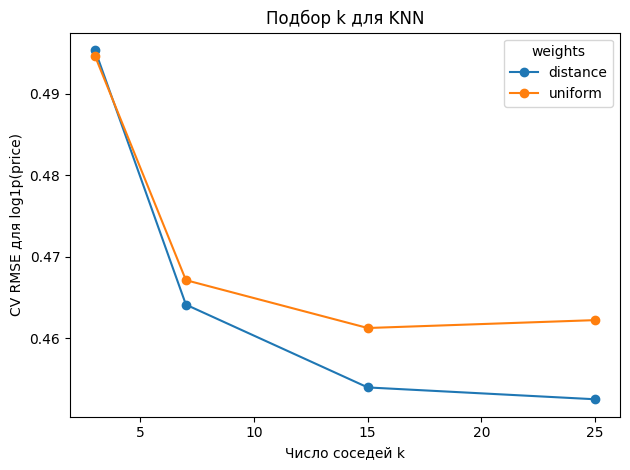

In [293]:
cv_results = pd.DataFrame(grid.cv_results_)
cv_table = pd.DataFrame({
    "k": cv_results["param_model__n_neighbors"].astype(int),
    "weights": cv_results["param_model__weights"],
    "CV RMSE (log)": -cv_results["mean_test_score"],
    "rank": cv_results["rank_test_score"]
})
display(cv_table.sort_values("rank"))

for weight, part in cv_table.groupby("weights"):
    plt.plot(part["k"], part["CV RMSE (log)"], marker="o", label=weight)
plt.xlabel("Число соседей k"); plt.ylabel("CV RMSE для log1p(price)")
plt.title("Подбор k для KNN"); plt.legend(title="weights"); plt.tight_layout(); plt.show()

**Как интерпретировать подбор k**: слишком маленькое k делает прогноз чрезмерно зависимым от отдельных объектов и может приводить к переобучению; слишком большое k чрезмерно сглаживает различия и может недообучаться. Выбираем комбинацию k и weights с наименьшим CV RMSE. Кросс-валидация даёт более устойчивый выбор, чем попытка подбирать k по тестовой ошибке.

In [294]:
best_k = int(grid.best_params_["model__n_neighbors"])
best_weights = grid.best_params_["model__weights"]
knn_best = grid.best_estimator_  # уже обучена GridSearchCV на X_knn_fit
print(f"KNN: k={best_k}, weights='{best_weights}', train объектов={len(X_train):,}")

KNN: k=25, weights='distance', train объектов=39,091


### Метрики качества:

- **MAE** — средняя абсолютная ошибка в долларах. Например, MAE = 40 означает, что абсолютное отклонение прогноза от фактической цены в среднем составляет 40 долларов за ночь.
- **RMSE** — корень из средней квадратичной ошибки; сильнее штрафует большие промахи, чем MAE.
- **Median AE** — медианная абсолютная ошибка, менее чувствительная к редким большим промахам.
- **R²** — коэффициент детерминации. Чем ближе к 1, тем лучше модель объясняет разброс цены относительно простого прогноза средним. На тесте R² может быть отрицательным, если модель хуже такого простого базового подхода.
- **RMSE log** — ошибка в логарифмическом масштабе, соответствующем функции обучения.

Чтобы оценка KNN не требовала вычислять расстояния для всех 39 тысяч обучающих объектов, ошибка `Train` считается на случайной выборке до 1 500 строк из train; `Test` считается на всей тестовой выборке. Поэтому train-метрики являются диагностической оценкой и могут быть оптимистичными, особенно для `weights='distance'`, а основную оценку обобщения дают CV и test.

Матрица ошибок не является естественной метрикой регрессии, потому что фактическая и предсказанная цены непрерывны. Позже мы дополнительно превратим цену в четыре интерпретируемых диапазона и построим матрицу только как вспомогательную диагностику.

In [295]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

baseline_log = y_train_log.median()
MODEL_PREDICTIONS = {}

def predict_log(model, X):
    return np.full(len(X), baseline_log) if model is None else model.predict(X)

def regression_metrics(y, pred_log):
    y, pred_log = np.asarray(y), np.asarray(pred_log)
    pred = np.maximum(0, np.expm1(pred_log))
    return {
        "MAE, USD": mean_absolute_error(y, pred),
        "RMSE, USD": mean_squared_error(y, pred) ** 0.5,
        "MedianAE, USD": median_absolute_error(y, pred),
        "R2, price": r2_score(y, pred),
        "RMSE, log": mean_squared_error(np.log1p(y), pred_log) ** 0.5
    }

def evaluate_model(model, name):
    idx = X_train.sample(n=min(1500, len(X_train)), random_state=991).index
    train_pred = predict_log(model, X_train.loc[idx])
    test_pred = predict_log(model, X_test)
    MODEL_PREDICTIONS[name] = {"train_log": train_pred, "test_log": test_pred}
    return {
        "Модель": name,
        **{f"Train {k}": v for k, v in regression_metrics(y_train.loc[idx], train_pred).items()},
        **{f"Test {k}": v for k, v in regression_metrics(y_test, test_pred).items()}
    }

initial_metrics = pd.DataFrame([
    evaluate_model(None, "Baseline: медиана"),
    evaluate_model(knn_best, f"KNN best k={best_k}")
]).set_index("Модель")
display(initial_metrics.round(3))

,"Train MAE, USD","Train RMSE, USD","Train MedianAE, USD","Train R2, price","Train RMSE, log","Test MAE, USD","Test RMSE, USD","Test MedianAE, USD","Test R2, price","Test RMSE, log"
Модель,,,,,,,,,,
Baseline: медиана,81.329,193.778,45.0,-0.056,0.698,82.205,199.835,45.000,-0.056,0.692
KNN best k=25,0.000,0.000,0.0,1.000,0.000,56.016,177.348,25.148,0.168,0.449


## 10. Сравниваем с другими методами

Сравним KNN с двумя моделями:

- **Линейная регрессия** — линейная регрессия с L2-регуляризацией. Она задаёт более простую форму зависимости, зато устойчива и часто служит полезным ориентиром.
- **Random Forest** — ансамбль деревьев, способный описывать нелинейности и взаимодействия признаков.

Для сравнения сохраняем одинаковое train/test-разбиение, одинаковые исходные признаки и обучение на `log1p(price)`. Каждая модель получает собственный пайплайн предобработки, который обучается только на тренировочных данных. Чтобы не затягивать выполнение, Random Forest обучается на случайной подвыборке до 12 000 объектов, как и KNN — на собственной подвыборке; test-метрики считаются на всех тестовых строках. Для окончательного производственного обучения лимиты можно увеличить, если хватает времени и памяти.

In [305]:
ridge = Pipeline([
    ("prep", make_preprocessor()),
    ("model", Ridge(alpha=10, solver="lsqr"))
]).fit(X_train, y_train_log)
print("Линейная регрессия обучена.")

Линейная регрессия обучена.


In [306]:
X_rf_fit = X_train.sample(n=min(12000, len(X_train)), random_state=2025)
random_forest = Pipeline([
    ("prep", make_preprocessor()),
    ("model", RandomForestRegressor(n_estimators=30, max_depth=15,
        min_samples_leaf=5, max_features=0.5, random_state=42, n_jobs=1))
]).fit(X_rf_fit, y_train_log.loc[X_rf_fit.index])
print(f"Random Forest обучен на {len(X_rf_fit):,} объектах.")

Random Forest обучен на 12,000 объектах.


In [307]:
other_results = pd.DataFrame([
    evaluate_model(ridge, "Линейная регрессия"),
    evaluate_model(random_forest, "Random Forest")
]).set_index("Модель")
results = pd.concat([initial_metrics, other_results])
display(results.round(3).sort_values("Test RMSE, USD"))

,"Train MAE, USD","Train RMSE, USD","Train MedianAE, USD","Train R2, price","Train RMSE, log","Test MAE, USD","Test RMSE, USD","Test MedianAE, USD","Test R2, price","Test RMSE, log"
Модель,,,,,,,,,,
KNN best k=25,0.000,0.000,0.000,1.000,0.000,56.016,177.348,25.148,0.168,0.449
Random Forest,53.111,165.774,23.754,0.227,0.423,56.250,177.734,24.525,0.164,0.442
Линейная регрессия,57.683,170.657,27.455,0.181,0.461,58.256,180.066,26.088,0.142,0.462
Baseline: медиана,81.329,193.778,45.000,-0.056,0.698,82.205,199.835,45.000,-0.056,0.692


### Фактическая цена и прогноз

На графике идеальные прогнозы лежали бы на диагонали `y = x`. Мы ограничиваем оси 99-м процентилем, чтобы основной массив был лучше виден, но все тестовые строки участвуют в метриках выше.

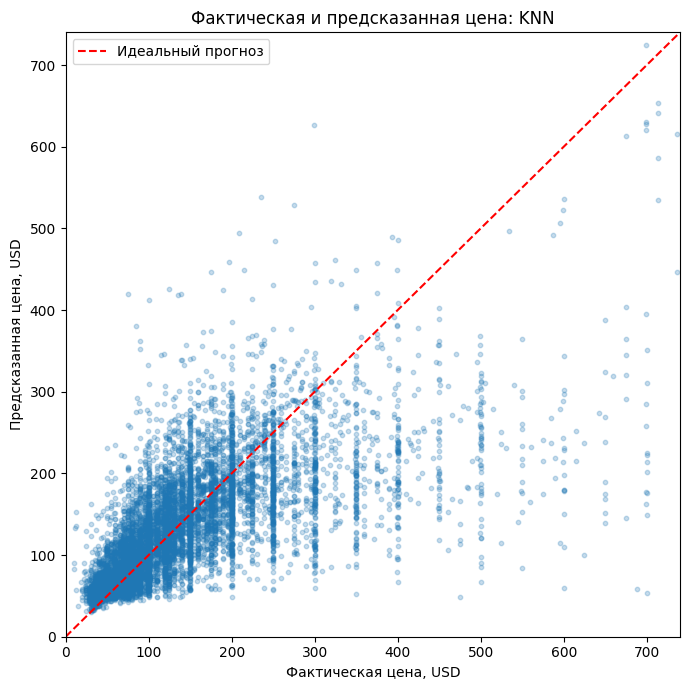

In [308]:

y_pred_test_knn = np.maximum(0, np.expm1(MODEL_PREDICTIONS[f"KNN best k={best_k}"]["test_log"]))
visual_cap = y_test.quantile(0.99)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_test_knn, alpha=0.25, s=10)
plt.plot([0, visual_cap], [0, visual_cap], "r--", label="Идеальный прогноз")
plt.xlim(0, visual_cap)
plt.ylim(0, visual_cap)
plt.xlabel("Фактическая цена, USD")
plt.ylabel("Предсказанная цена, USD")
plt.title("Фактическая и предсказанная цена: KNN")
plt.legend()
plt.tight_layout()
plt.show()

### Матрица ошибок для ценовых диапазонов

Это не основная метрика регрессии. Чтобы получить матрицу, разделим цену на четыре группы по квартилям, рассчитанным **только по train**: низкая, средне-низкая, средне-высокая и высокая. После этого проверим, в какой диапазон попадают фактические цены тестовых объектов и прогноз KNN.

Матрица помогает увидеть, путает ли модель соседние ценовые группы или, например, предсказывает дешёвое жильё как дорогое. При переводе непрерывной переменной в категории часть информации теряется, поэтому MAE/RMSE/R² всё равно остаются основными метриками.

,Низкая,Средне-низкая,Средне-высокая,Высокая
Низкая,1606,692,146,10
Средне-низкая,500,991,774,111
Средне-высокая,79,406,1324,649
Высокая,23,109,799,1554


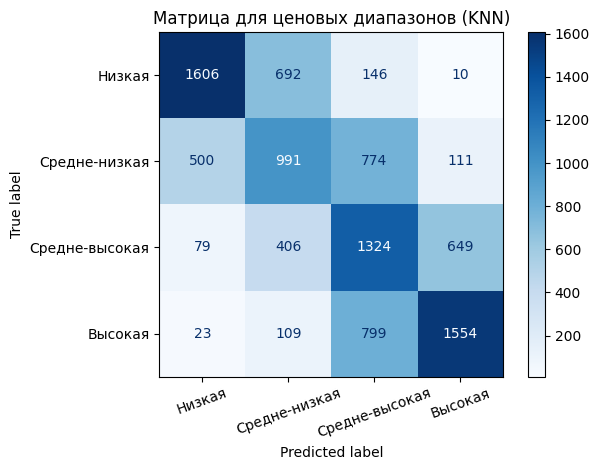

In [300]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

q = y_train.quantile([.25, .50, .75]).to_numpy()
bins, labels = [-np.inf, *q, np.inf], ["Низкая", "Средне-низкая", "Средне-высокая", "Высокая"]
true = pd.cut(y_test, bins=bins, labels=labels, include_lowest=True)
pred = pd.cut(y_pred_test_knn, bins=bins, labels=labels, include_lowest=True)
cm = confusion_matrix(true, pred, labels=labels)
display(pd.DataFrame(cm, index=labels, columns=labels))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Матрица для ценовых диапазонов (KNN)"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

### Важность признаков в Random Forest

У случайного леса можно посмотреть встроенную важность признаков. Она отражает вклад признака в разбиения деревьев по критерию модели, но не является причинным эффектом. При One-Hot Encoding одна исходная категория может превратиться во множество столбцов.

,Важность признака
cat__room_type_Entire home/apt,0.385283
num__longitude,0.133561
cat__room_type_Private room,0.105026
num__latitude,0.090904
num__availability_365,0.064442
cat__neighbourhood_group_Manhattan,0.043591
num__minimum_nights,0.036399
num__reviews_per_month,0.032189
num__number_of_reviews,0.029632
num__calculated_host_listings_count,0.018912


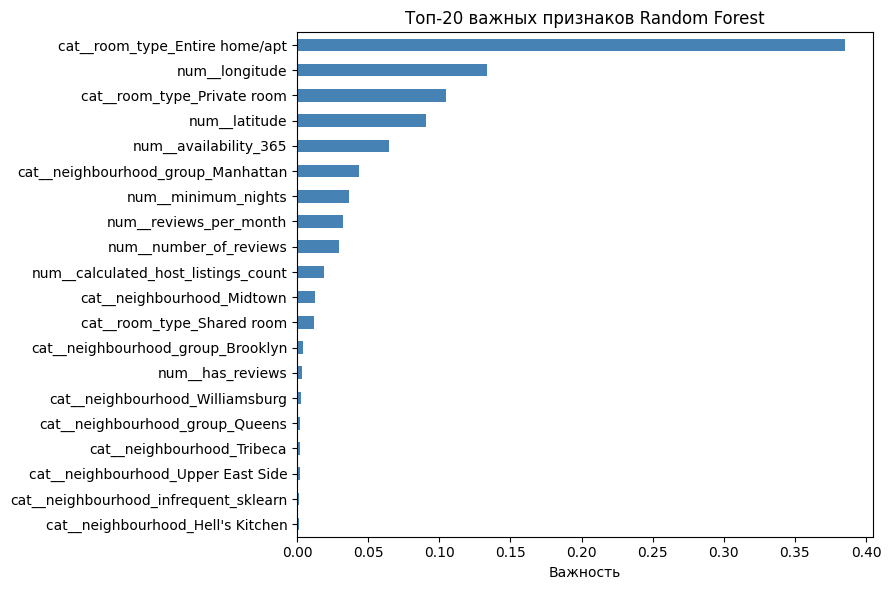

In [301]:
names = random_forest.named_steps["prep"].get_feature_names_out()
importance = pd.Series(random_forest.named_steps["model"].feature_importances_, index=names).nlargest(20)
display(importance.to_frame("Важность признака"))
importance.sort_values().plot.barh(figsize=(9, 6), color="steelblue")
plt.title("Топ-20 важных признаков Random Forest"); plt.xlabel("Важность"); plt.tight_layout(); plt.show()

## 11. Коррелированные признаки: проверка и эксперимент

Почему это может иметь значение? В KNN расстояние складывается из различий по всем признакам. Если два почти дублирующих признака кодируют одну информацию, она может получить двойной вес в расстоянии. В линейной модели сильная корреляция может затруднять интерпретацию коэффициентов, хотя Линейная регрессия частично стабилизирует оценки.

Ниже найдём пары числовых признаков с `|corr| >= 0.90`. Если есть такие пары, автоматически оставим тот признак из каждой пары, у которого выше абсолютная корреляция с `log_price`, а затем сравним KNN с обычным набором признаков и сокращённым набором. Если подходящих пар нет, код сообщит об этом — удалять признаки только ради удаления не требуется.

In [302]:
feature_corr = train_data[NUM_FEATURES].corr(numeric_only=True)
target_corr = train_data[NUM_FEATURES + ["log_price"]].corr(numeric_only=True)["log_price"].abs()
high_corr_pairs = [(a, b, feature_corr.loc[a, b])
    for i, a in enumerate(NUM_FEATURES) for b in NUM_FEATURES[i + 1:]
    if abs(feature_corr.loc[a, b]) >= 0.90]
to_drop = {a if target_corr[a] < target_corr[b] else b for a, b, _ in high_corr_pairs}
if high_corr_pairs:
    display(pd.DataFrame(high_corr_pairs, columns=["Признак 1", "Признак 2", "Корреляция"]))
else:
    print("Пар с |corr| >= 0.90 не найдено.")
NUM_FEATURES_REDUCED = [c for c in NUM_FEATURES if c not in to_drop]
print("Удаляем:", sorted(to_drop), "| Числовых признаков:", len(NUM_FEATURES), "→", len(NUM_FEATURES_REDUCED))

Пар с |corr| >= 0.90 не найдено.
Удаляем: [] | Числовых признаков: 8 → 8


In [303]:
if to_drop:
    knn_reduced = make_knn(best_k, best_weights, NUM_FEATURES_REDUCED).fit(X_knn_fit, y_knn_fit_log)
    X_test_corr = X_test.sample(n=min(2000, len(X_test)), random_state=42)
    y_test_corr = y_test.loc[X_test_corr.index]
    table = pd.DataFrame([
        {"Модель": "KNN: все признаки", **regression_metrics(y_test_corr, knn_best.predict(X_test_corr))},
        {"Модель": "KNN: без коррелированных", **regression_metrics(y_test_corr, knn_reduced.predict(X_test_corr))}
    ]).set_index("Модель")
    display(table.round(3))
else:
    print("Сильно коррелированных числовых признаков не найдено; удалять нечего.")

Сильно коррелированных числовых признаков не найдено; удалять нечего.


In [309]:
best_name = results["Test RMSE, USD"].idxmin()
best = results.loc[best_name]
print(f"После очистки: {len(data):,} объявлений; train/test: {len(X_train):,}/{len(X_test):,}.")
print(f"Лучшая модель по тестовому RMSE: {best_name} (RMSE={best['Test RMSE, USD']:.2f} $, "
      f"MAE={best['Test MAE, USD']:.2f} $, R²={best['Test R2, price']:.3f}).")
print(f"KNN выбрал k={best_k}, weights='{best_weights}' по 3-fold CV.")
print("Основные метрики регрессии: MAE, RMSE и R². Матрица ценовых диапазонов — дополнительная диагностика.")
display(results[["Train MAE, USD", "Test MAE, USD", "Train RMSE, USD", "Test RMSE, USD",
                 "Train R2, price", "Test R2, price", "Test RMSE, log"]].round(3).sort_values("Test RMSE, USD"))

После очистки: 48,864 объявлений; train/test: 39,091/9,773.
Лучшая модель по тестовому RMSE: KNN best k=25 (RMSE=177.35 $, MAE=56.02 $, R²=0.168).
KNN выбрал k=25, weights='distance' по 3-fold CV.
Основные метрики регрессии: MAE, RMSE и R². Матрица ценовых диапазонов — дополнительная диагностика.


,"Train MAE, USD","Test MAE, USD","Train RMSE, USD","Test RMSE, USD","Train R2, price","Test R2, price","Test RMSE, log"
Модель,,,,,,,
KNN best k=25,0.000,56.016,0.000,177.348,1.000,0.168,0.449
Random Forest,53.111,56.250,165.774,177.734,0.227,0.164,0.442
Линейная регрессия,57.683,58.256,170.657,180.066,0.181,0.142,0.462
Baseline: медиана,81.329,82.205,193.778,199.835,-0.056,-0.056,0.692


## Выводы

1. Решалась задача **регрессии**: предсказание цены за ночь (`price`) для объявлений Airbnb в Нью-Йорке на основе характеристик жилья, местоположения и активности объявления. Исходный набор данных содержал 48 895 объявлений и 16 столбцов. После очистки осталось 48 864 объявления, из которых 80% (39 091) использовались для обучения, а 20% (9 773) — для тестирования.

2. **Главная особенность данных** — значительный разброс цен и их правосторонняя асимметрия.

3. **Обработка выбросов и некорректных значений.** Из исходных данных исключены 11 объявлений с нулевой или неположительной ценой и 20 объявлений с ценой выше 5 000 долларов за ночь. Последние составляют около 0,041% исходного набора.  Остальные потенциальные выбросы исследовались с помощью правила IQR, но автоматически не удалялись. Для уменьшения влияния асимметрии целевая переменная преобразовывалась с помощью `log1p(price)`.

4. **Пропуски, категориальные признаки и нормализация.** В столбце `reviews_per_month` было 10 040 пропусков, и все они соответствовали объявлениям без отзывов. Поэтому пропущенные значения заменили нулями и добавили бинарный признак `has_reviews`. Для модели использовались 8 числовых и 3 категориальных признака: `neighbourhood_group`, `neighbourhood` и `room_type`.

5. **Регрессия методом k ближайших соседей (KNN).** Оптимальные параметры по трёхкратной кросс-валидации — `k = 25` и `weights = 'distance'`. На тестовой выборке KNN показал MAE ≈ 56,016 доллара, RMSE ≈ 177,348 доллара и \(R^2 \approx 0{,}168\).

6. **Сравнение моделей.** Наилучшие результаты в проведённом эксперименте показал KNN, за ним следовали Random Forest и Линейная регрессия. На тестовой выборке получены следующие значения:

   | Модель | MAE, USD | RMSE, USD | \(R^2\) |
   |---|---:|---:|---:|
   | Random Forest | 56,25 | 177,734 | 0,164 |
   | KNN | 56,01 | 177,348 | 0,168 |
   | Линейная регрессия | 58,256 | 180,066 | 0,142 |
   | Прогноз медианой | 82,205 | 199,835 | −0,056 |

   Random Forest показал наименьшие ошибки среди рассмотренных моделей. Вероятное объяснение — способность деревьев учитывать нелинейные зависимости и взаимодействия между признаками. При этом сравнение следует интерпретировать с учётом того,  Random Forest обучался на выборке 12 000, а KNN и линейная регрессия — на всей обучающей выборке.

7. **Коррелированные признаки.** При проверке числовых признаков не обнаружено пар с абсолютным коэффициентом корреляции не менее 0,90.

8. **Итоговые выводы и ограничения.**  Распределение задачи, сильно скошено вправо, что было учтено логарифмическим преобразованием целевой переменной. Лучший результат показал KNN, но \(R^2 \approx 0{,}168\) означает, что модель объясняет лишь около 16-17% вариативности цены на тестовой выборке. Следовательно, качество прогнозирования остаётся ограниченным: цена зависит от факторов, которые отсутствуют в выбранных признаках или не полностью отражены простой моделью.